LAPORAN EVALUASI MODEL KLASIFIKASI PEMICU DEFORESTASI (BART SLAGTER WUR)
                  precision    recall  f1-score   support

Jalan_Penebangan     1.0000    1.0000    1.0000        50
Pertanian_Rakyat     1.0000    1.0000    1.0000        50
  Sawit_Industri     1.0000    1.0000    1.0000        50
  Tambang_Ilegal     1.0000    1.0000    1.0000        50

        accuracy                         1.0000       200
       macro avg     1.0000    1.0000    1.0000       200
    weighted avg     1.0000    1.0000    1.0000       200


--- KONTRIBUSI FITUR MULTI-SENSOR DALAM MEMBEDAKAN PEMICU ---
- Elongasi_Shape    : 29.41%
- Luas_Hektare      : 25.32%
- SAR_VH_dB         : 20.39%
- NBR_Drop          : 9.83%
- NDVI_Drop         : 8.73%
- SAR_Ratio_VHVV    : 6.32%

SIMULASI PENERIMAAN 3 PERINGATAN DEFORESTASI BARU DI HUTAN BENGKULU
Alert #1 [Kawasan Penyangga TNKS Blok Air Rami]:
  -> Terdeteksi Pemicu : Sawit_Industri
  -> Tingkat Keyakinan : 100.00%
  -> REKOMENDASI PATROLI: [PRIORITA

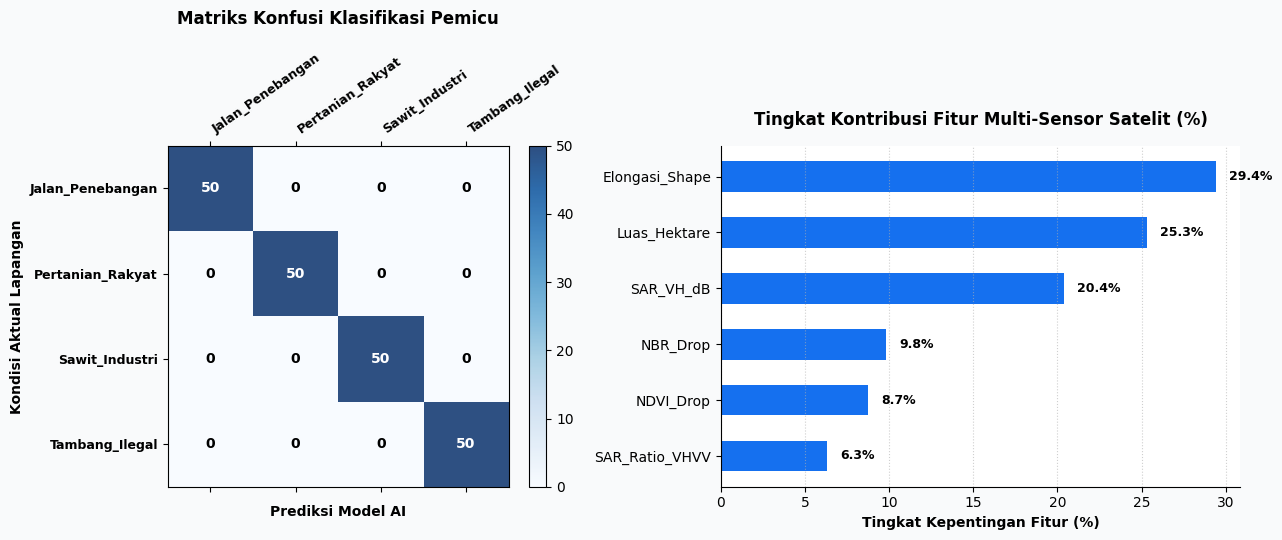

In [1]:
"""
SISTEM OTOMASI ATRIBUSI PEMICU DEFORESTASI (FOREST DRIVER ATTRIBUTION)
Berdasarkan Riset Dr. Bart Slagter (Wageningen University & Research / WUR):
- Fusi Data Multi-Sensor: Sentinel-1 SAR (Radar C-Band) + Sentinel-2 Optik Multispektral
- Klasifikasi 4 Direct Drivers: Sawit Industri, Pertanian Rakyat, Tambang Ilegal, Jalan Penebangan
"""

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt

# ==============================================================================
# 1. SIMULASI DATASET MULTI-SENSOR PERINGATAN DEFORESTASI (DATA GENERATION)
# ==============================================================================
np.random.seed(42)
n_samples_per_class = 250
total_samples = n_samples_per_class * 4

# Driver 1: Perkebunan Sawit Industri (Area Luas, Bentuk Blok Kompak, Penurunan NDVI Sedang)
sawit = {
    'Luas_Hektare': np.random.uniform(15.0, 85.0, n_samples_per_class),
    'Elongasi_Shape': np.random.uniform(0.70, 0.95, n_samples_per_class), # Kompak / Persegi
    'NDVI_Drop': np.random.uniform(0.35, 0.60, n_samples_per_class),
    'NBR_Drop': np.random.uniform(0.30, 0.55, n_samples_per_class),
    'SAR_VH_dB': np.random.uniform(-17.5, -15.0, n_samples_per_class),
    'SAR_Ratio_VHVV': np.random.uniform(0.35, 0.50, n_samples_per_class),
    'Driver': 'Sawit_Industri'
}

# Driver 2: Pertanian Rakyat / Ladang Campuran (Area Kecil < 3 Ha, Bentuk Tidak Beraturan)
rakyat = {
    'Luas_Hektare': np.random.uniform(0.5, 3.2, n_samples_per_class),
    'Elongasi_Shape': np.random.uniform(0.40, 0.75, n_samples_per_class),
    'NDVI_Drop': np.random.uniform(0.20, 0.45, n_samples_per_class),
    'NBR_Drop': np.random.uniform(0.15, 0.40, n_samples_per_class),
    'SAR_VH_dB': np.random.uniform(-15.5, -13.0, n_samples_per_class),
    'SAR_Ratio_VHVV': np.random.uniform(0.45, 0.60, n_samples_per_class),
    'Driver': 'Pertanian_Rakyat'
}

# Driver 3: Pertambangan Ilegal (Bukaan Tanah Terbuka Ekstrem, Dekat Sungai, Backscatter Sangat Rendah)
tambang = {
    'Luas_Hektare': np.random.uniform(3.0, 25.0, n_samples_per_class),
    'Elongasi_Shape': np.random.uniform(0.50, 0.85, n_samples_per_class),
    'NDVI_Drop': np.random.uniform(0.65, 0.90, n_samples_per_class), # Tanah gundul total
    'NBR_Drop': np.random.uniform(0.60, 0.85, n_samples_per_class),
    'SAR_VH_dB': np.random.uniform(-22.0, -18.5, n_samples_per_class), # Hilang biomassa total
    'SAR_Ratio_VHVV': np.random.uniform(0.20, 0.35, n_samples_per_class),
    'Driver': 'Tambang_Ilegal'
}

# Driver 4: Jalan Penebangan / Logging Roads (Area Sedang, Sangat Memanjang/Linear, Rasio Elongasi Rendah)
logging = {
    'Luas_Hektare': np.random.uniform(1.5, 12.0, n_samples_per_class),
    'Elongasi_Shape': np.random.uniform(0.05, 0.28, n_samples_per_class), # Bentuk koridor garis panjang
    'NDVI_Drop': np.random.uniform(0.40, 0.70, n_samples_per_class),
    'NBR_Drop': np.random.uniform(0.35, 0.65, n_samples_per_class),
    'SAR_VH_dB': np.random.uniform(-18.0, -14.5, n_samples_per_class),
    'SAR_Ratio_VHVV': np.random.uniform(0.30, 0.48, n_samples_per_class),
    'Driver': 'Jalan_Penebangan'
}

# Menggabungkan Dataset
df_deforest = pd.concat([pd.DataFrame(sawit), pd.DataFrame(rakyat),
                         pd.DataFrame(tambang), pd.DataFrame(logging)], ignore_index=True)


# ==============================================================================
# 2. PEMBAGIAN DATA & PELATIHAN MODEL ATRIBUSI (TRAINING PIPELINE)
# ==============================================================================
fitur = ['Luas_Hektare', 'Elongasi_Shape', 'NDVI_Drop', 'NBR_Drop', 'SAR_VH_dB', 'SAR_Ratio_VHVV']
X = df_deforest[fitur]
y = df_deforest['Driver']

# Pembagian 80% Training Data dan 20% Unseen Testing Data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

# Pelatihan Model Random Forest Classifier (Standar Industri ForestNet)
rf_model = RandomForestClassifier(n_estimators=150, max_depth=8, random_state=42)
rf_model.fit(X_train, y_train)

# Prediksi pada Data Uji
y_pred = rf_model.predict(X_test)


# ==============================================================================
# 3. EVALUASI MODEL & ANALISIS KEPENTINGAN FITUR SENSOR
# ==============================================================================
print("=====================================================================")
print("LAPORAN EVALUASI MODEL KLASIFIKASI PEMICU DEFORESTASI (BART SLAGTER WUR)")
print("=====================================================================")
print(classification_report(y_test, y_pred, digits=4))

# Kepentingan Fitur Sensor (Feature Importance)
importances = rf_model.feature_importances_
df_imp = pd.DataFrame({'Fitur': fitur, 'Importance': importances}).sort_values('Importance', ascending=False)

print("\n--- KONTRIBUSI FITUR MULTI-SENSOR DALAM MEMBEDAKAN PEMICU ---")
for _, r in df_imp.iterrows():
    print(f"- {r['Fitur']:<18}: {r['Importance']*100:.2f}%")


# ==============================================================================
# 4. SIMULASI KASUS INFERENSI NYATA PADA ALERT BARU DI PROVINSI BENGKULU
# ==============================================================================
print("\n=====================================================================")
print("SIMULASI PENERIMAAN 3 PERINGATAN DEFORESTASI BARU DI HUTAN BENGKULU")
print("=====================================================================")

alert_baru = pd.DataFrame([
    # Alert A: Area 42 Ha, bentuk persegi kompak, penurunan kanopi masif
    [42.5, 0.88, 0.48, 0.42, -16.2, 0.41],
    # Alert B: Area 2.8 Ha, koridor sangat panjang memanjang di tengah rimba
    [3.2, 0.12, 0.55, 0.49, -16.8, 0.38],
    # Alert C: Area 8.5 Ha, tanah terbuka gundul total, backscatter anjlok di bantaran sungai
    [9.1, 0.65, 0.78, 0.72, -20.5, 0.26]
], columns=fitur)

prediksi_alert = rf_model.predict(alert_baru)
probabilitas = rf_model.predict_proba(alert_baru)

lokasi = ["Kawasan Penyangga TNKS Blok Air Rami", "Hutan Lindung Bukit Daun", "Kawasan Konservasi Hutan Produksi Seluma"]

for i in range(len(alert_baru)):
    max_prob = np.max(probabilitas[i]) * 100
    print(f"Alert #{i+1} [{lokasi[i]}]:")
    print(f"  -> Terdeteksi Pemicu : {prediksi_alert[i]}")
    print(f"  -> Tingkat Keyakinan : {max_prob:.2f}%")
    if prediksi_alert[i] in ['Tambang_Ilegal', 'Jalan_Penebangan']:
        print("  -> REKOMENDASI PATROLI: [PRIORITAS 1 - SEGERA TERJUNKAN TIM GAKKUM]\n")
    else:
        print("  -> REKOMENDASI PATROLI: [PRIORITAS 2 - MONITORING CITRA RESOLUSI TINGGI]\n")


# ==============================================================================
# 5. VISUALISASI MATRIKS KONFUSI & KONTRIBUSI FITUR (TUFTE MINIMALIST)
# ==============================================================================
labels = sorted(list(y.unique()))
cm = confusion_matrix(y_test, y_pred, labels=labels)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))
fig.patch.set_facecolor('#F9FAFB')

# Plot 1: Matriks Konfusi
cax = ax1.matshow(cm, cmap='Blues', alpha=0.85)
fig.colorbar(cax, ax=ax1, fraction=0.046, pad=0.04)
ax1.set_xticks(range(len(labels)))
ax1.set_yticks(range(len(labels)))
ax1.set_xticklabels(labels, rotation=35, ha='left', fontsize=9, fontweight='bold')
ax1.set_yticklabels(labels, fontsize=9, fontweight='bold')
ax1.set_title('Matriks Konfusi Klasifikasi Pemicu', fontsize=12, fontweight='bold', pad=20)
ax1.set_xlabel('Prediksi Model AI', fontweight='bold', labelpad=10)
ax1.set_ylabel('Kondisi Aktual Lapangan', fontweight='bold')

for i in range(len(labels)):
    for j in range(len(labels)):
        ax1.text(j, i, str(cm[i, j]), ha='center', va='center',
                 color='black' if cm[i, j] < cm.max()/2 else 'white', fontweight='bold')

# Plot 2: Kontribusi Fitur Multi-Sensor
ax2.set_facecolor('#FFFFFF')
bars = ax2.barh(df_imp['Fitur'], df_imp['Importance']*100, color='#1570EF', height=0.55)
ax2.invert_yaxis()
ax2.set_title('Tingkat Kontribusi Fitur Multi-Sensor Satelit (%)', fontsize=12, fontweight='bold', pad=15)
ax2.set_xlabel('Tingkat Kepentingan Fitur (%)', fontweight='bold')
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
ax2.xaxis.grid(True, linestyle=':', alpha=0.6)

for bar in bars:
    w = bar.get_width()
    ax2.text(w + 0.8, bar.get_y() + bar.get_height()/2, f'{w:.1f}%', va='center', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.savefig('deforestation_attribution_evaluation.png', dpi=300, bbox_inches='tight')
print("[BERHASIL] Gambar evaluasi model tersimpan sebagai 'deforestation_attribution_evaluation.png'.")
